# Distribution and scatter plots of all factors

This notebook adds two figures to the descriptive analysis of notebook 6:

1. A **boxplot** of charging point density, which shows the distribution and makes outliers visible.
2. **Scatter plots** of charging point density against each explanatory variable, with a least-squares regression line.

The choice of plot follows the data relationship we want to show: a boxplot for a **distribution** with outliers, and scatter plots for the **correlation** between two numerical variables.

**Input:** `data/processed/all_variables_per_municipality.csv`, created by notebook 6. Run notebook 6 first.

**Outputs:** `figures/figure_boxplot_charging_point_density.png`, `figures/figure_scatter_all_factors.png`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PROCESSED = "../data/processed/"
FIGURES = "../figures/"

## 1. Load the data

The same readable English labels are used as in notebook 6.

In [2]:
df = pd.read_csv(PROCESSED + "all_variables_per_municipality.csv")

LABELS = {
    "laadpunten_per_1000_huishoudens": "Charging points per 1,000 households",
    "gem_gestandaardiseerd_inkomen_keur": "Mean standardised income (k€)",
    "med_gestandaardiseerd_inkomen_keur": "Median standardised income (k€)",
    "jongeren_onder_25_pct": "Residents under 25 (%)",
    "ouderen_65plus_pct": "Residents 65+ (%)",
    "linkse_stemmen_pct": "Left-wing vote share (%)",
    "linkse_stemmen_smal_pct": "Left-wing vote share, narrow (%)",
    "hoogopgeleid_pct": "Highly educated (%)",
    "bevolkingsdichtheid": "Population density (inh./km²)",
    "meergezinswoning_pct": "Apartments (% of dwellings)",
}
variables = [c for c in LABELS if c in df.columns]
data = df[variables].rename(columns=LABELS)
target = "Charging points per 1,000 households"

print("Municipalities:", len(data))

Municipalities: 342


## 2. Boxplot of charging point density

The box runs from the first quartile (Q1) to the third quartile (Q3); the red line is the median. Values more than 1.5 × the interquartile range (IQR = Q3 − Q1) above Q3 or below Q1 are shown as separate points: these are the outliers. Each outlier is labelled with its municipality name.

/var/folders/5l/f73_yvzx7x78mwq61h6pghqw0000gn/T/ipykernel_57005/20882010.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(y.dropna(), vert=False, widths=0.5, patch_artist=True,


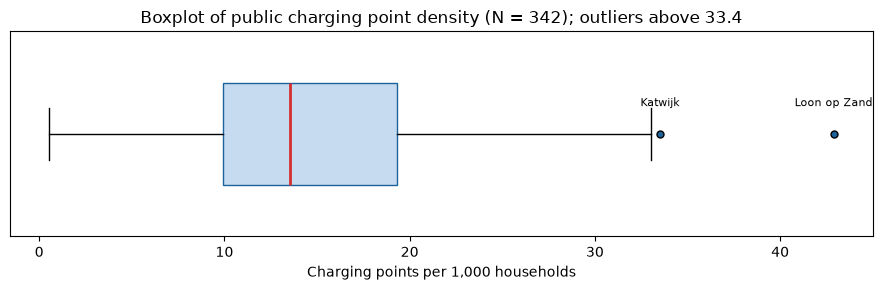

Outliers: Loon op Zand (42.9), Katwijk (33.5)


In [3]:
# Boxplot of charging point density, with outliers labelled
y = data["Charging points per 1,000 households"]
names = df.loc[data.index, "gemeente"]

q1, q3 = y.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
lower_fence = q1 - 1.5 * (q3 - q1)
outliers = y[(y > upper_fence) | (y < lower_fence)]

fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(y.dropna(), vert=False, widths=0.5, patch_artist=True,
           boxprops={"facecolor": "#c6dbef", "edgecolor": "#1d639b"},
           medianprops={"color": "#d32f2f", "linewidth": 2},
           flierprops={"marker": "o", "markerfacecolor": "#1d639b", "markersize": 5})

# Label every outlier with its municipality name
for idx, value in outliers.items():
    ax.annotate(names[idx], (value, 1), textcoords="offset points", xytext=(0, 20),
                ha="center", fontsize=8)

ax.set_yticks([])
ax.set_xlabel("Charging points per 1,000 households")
ax.set_title(f"Boxplot of public charging point density (N = {y.notna().sum()}); "
             f"outliers above {upper_fence:.1f}")
plt.tight_layout()
plt.savefig(FIGURES + "figure_boxplot_charging_point_density.png", dpi=200)
plt.show()

print("Outliers:", ", ".join(f"{names[i]} ({v:.1f})" for i, v in outliers.sort_values(ascending=False).items()))

## 3. Scatter plots of all factors

Each panel shows charging point density against one explanatory variable. The red line is the least-squares fit and the shaded band its 95% confidence interval; the Pearson correlation r and the number of municipalities N are given in the title.

Population density is strongly right-skewed, so it is plotted on a logarithmic axis and the line is fitted on log(density), as in the regression (notebook 7).

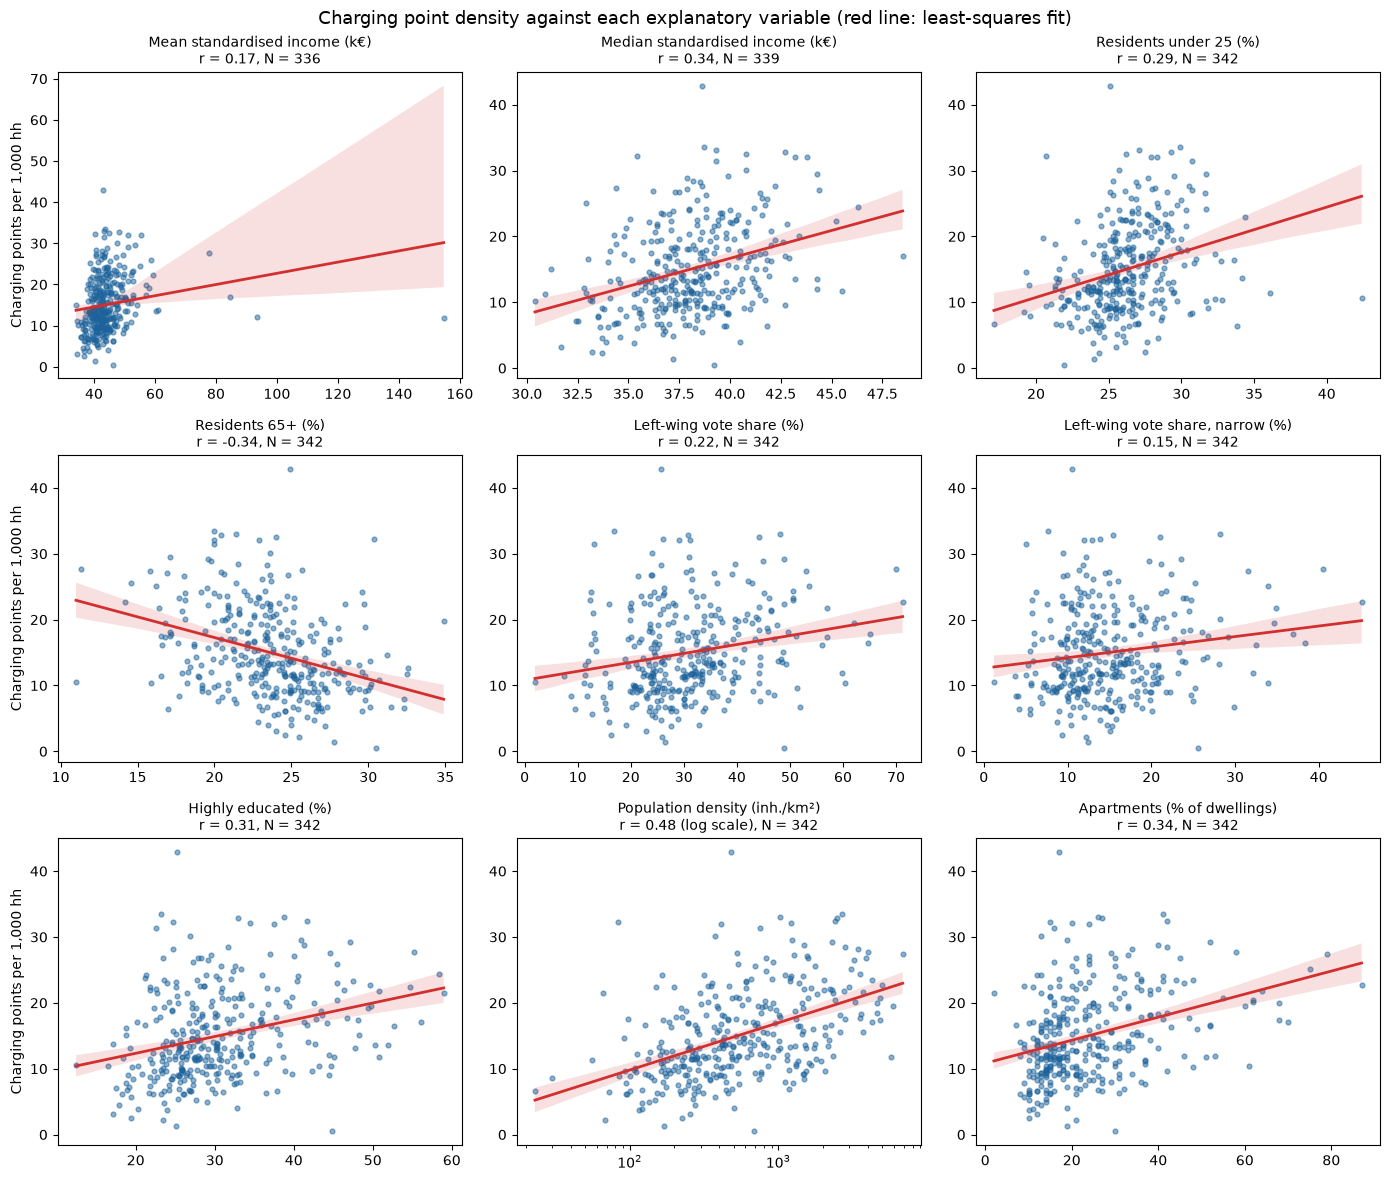

In [4]:
# Scatter plots of charging point density against each explanatory variable,
# with a least-squares regression line and Pearson r in the title
explanatory = [c for c in data.columns if c != target]
n_cols = 3
n_rows = -(-len(explanatory) // n_cols)  # round up

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
for ax, col in zip(axes.flat, explanatory):
    pair = data[[col, target]].dropna()
    r = stats.pearsonr(pair[col], pair[target])[0]
    # Population density is strongly skewed: plot on a log axis and fit the line on log(density)
    log_x = col.startswith("Population density")
    sns.regplot(data=pair, x=col, y=target, ax=ax, logx=log_x,
                scatter_kws={"s": 12, "alpha": 0.5, "color": "#1d639b"},
                line_kws={"color": "#d32f2f", "linewidth": 2})
    if log_x:
        ax.set_xscale("log")
        r = stats.pearsonr(np.log(pair[col]), pair[target])[0]
        ax.set_title(f"{col}\nr = {r:.2f} (log scale), N = {len(pair)}", fontsize=10)
    else:
        ax.set_title(f"{col}\nr = {r:.2f}, N = {len(pair)}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Charging points per 1,000 hh" if ax in axes[:, 0] else "")

for ax in axes.flat[len(explanatory):]:
    ax.set_visible(False)

fig.suptitle("Charging point density against each explanatory variable (red line: least-squares fit)", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES + "figure_scatter_all_factors.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Interpretation

> ** Still to do**